# 04 — HOG + KNN / SVM / Random Forest

**Course pipeline** (slides 111 and 133): *image → descriptor → supervised classifier*. Here:
- **image** = the 64 × 64 crop of the person (notebook 03);
- **descriptor** = **HOG** (Histogram of Oriented Gradients), which captures **shape and contours**: exactly what changes between standing and lying;
- **classifiers** = **KNN, SVM, Random Forest**, as in the course.

**Two levels of answer:**
1. **Frame:** what is the person's posture: *not lying*, *falling* or *lying*? This is the course task "classification d'images entières".
2. **Video:** fall or no fall? We summarise the frame answers of each video (same idea as the baseline, notebook 02).

In [1]:
from pathlib import Path
import re, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog

ROOT = Path("..") / "data" / "raw" / "urfd"
PROC = Path("..") / "data" / "processed"
PHASES = {-1: "not lying", 0: "falling", 1: "lying"}

def frames_of(video):
    files = (ROOT / "rgb" / video).rglob("*.png")
    return sorted((int(re.search(r"-(\d+)\.png$", p.name).group(1)), p) for p in files)

def crop_person(image, box, size=128):   # same function as notebook 03
    x, y, w, h = box
    side = int(max(w, h) * 1.1)
    cx, cy = x + w // 2, y + h // 2
    padded = cv2.copyMakeBorder(image, side, side, side, side, cv2.BORDER_CONSTANT, value=0)
    x0, y0 = cx - side // 2 + side, cy - side // 2 + side
    return cv2.resize(padded[y0:y0 + side, x0:x0 + side], (size, size))

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]

💡 **Interpretation:** setup only: paths, the crop function of notebook 03 and the frame labels (the answers the classifiers learn).

## Step 1 — The person crops (made once, reused in notebooks 04-07)

For every frame where notebook 03 found the person, we cut a **64 × 64** colour crop. Reading the 11,000 images takes about 5 minutes, so the crops are saved in `crops64.npz` and simply loaded afterwards.
We only keep frames that have a label, because the classifier needs the answer to learn and to be tested.

In [2]:
CROPS = PROC / "crops64.npz"
if not CROPS.exists():
    boxes = pd.read_csv(PROC / "person_boxes.csv").dropna().astype({"x": int, "y": int, "w": int, "h": int})
    crops = []
    for video, d in boxes.groupby("video", sort=False):
        files = dict(frames_of(video))
        for r in d.itertuples():
            image = cv2.cvtColor(cv2.imread(str(files[r.frame])), cv2.COLOR_BGR2RGB)
            crops.append(crop_person(image, (r.x, r.y, r.w, r.h), size=64))
    np.savez_compressed(CROPS, crops=np.stack(crops), video=np.array(boxes.video.tolist(), dtype="U8"),
                        frame=boxes.frame.to_numpy())

z = np.load(CROPS)
frames = pd.DataFrame({"video": z["video"], "frame": z["frame"]}).merge(labels, on=["video", "frame"], how="left")
keep = frames.frame_label.notna().to_numpy()
crops, frames = z["crops"][keep], frames[keep].reset_index(drop=True)
frames["phase"] = frames.frame_label.map(PHASES)
print(crops.shape)
print(frames.phase.value_counts())

(11027, 64, 64, 3)
phase
not lying    7054
lying        2256
falling      1717
Name: count, dtype: int64


💡 **Interpretation:** **11,027 labelled crops** of 64 × 64 × 3 (the 94% of frames where notebook 03 found the person). The classes are unbalanced: 7,054 *not lying*,
2,256 *lying* and only 1,717 *falling*, because a fall lasts about 1 second while people stand for most of the video.

## Step 2 — What HOG sees

The course's 6 steps (slides 112-115): grey levels → gradient of every pixel (Sobel) → **cells** → one histogram of **9 orientations** per cell (votes weighted by the gradient magnitude) → **blocks of 2 × 2 cells** normalised (robust to lighting) → everything concatenated in one vector.

The picture on the right of each pair draws, in every cell, the dominant edge directions.

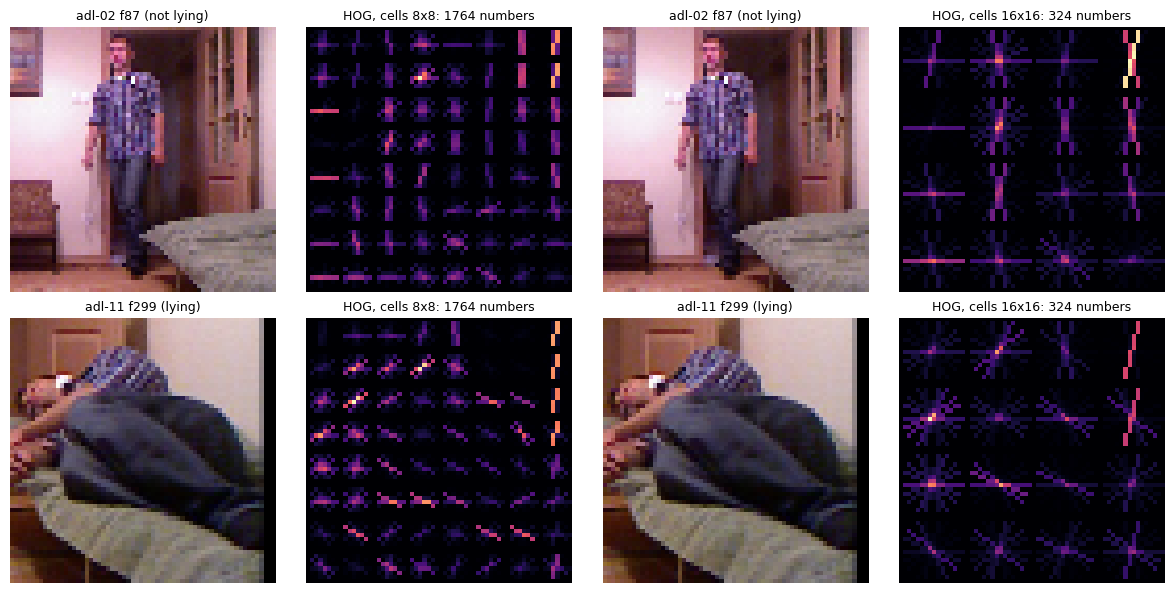

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
examples = [frames[frames.phase == p].index[200] for p in ["not lying", "lying"]]
for row, i in zip(axes, examples):
    gray = cv2.cvtColor(crops[i], cv2.COLOR_RGB2GRAY)
    for col, cell in enumerate([8, 16]):
        vec, picture = hog(gray, orientations=9, pixels_per_cell=(cell, cell), cells_per_block=(2, 2), visualize=True)
        row[2 * col].imshow(crops[i]); row[2 * col].set_title(f"{frames.video[i]} f{frames.frame[i]} ({frames.phase[i]})", fontsize=9)
        row[2 * col + 1].imshow(picture, cmap="magma"); row[2 * col + 1].set_title(f"HOG, cells {cell}x{cell}: {len(vec)} numbers", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

💡 **Interpretation:** standing gives mostly **vertical** edges along the body; lying gives **diagonal and horizontal** edges: HOG turns the posture into numbers.
It also captures background edges (door frame, image border on the right): the crop still contains some room, which adds noise.

## Step 3 — HOG for every crop

We use **16 × 16-pixel cells** → 4 × 4 cells, 3 × 3 blocks of 2 × 2 cells, × 9 orientations = **324 numbers per frame**.

Why not the course's 8 × 8 cells? On our 64 × 64 crops they give 1,764 numbers; we tested both: the SVM is only slightly better with 8 × 8 (frame accuracy 0.874 vs 0.859) but takes **11 minutes instead of 1**. For a notebook we keep the faster version.

In [4]:
t = time.time()
X = np.stack([hog(cv2.cvtColor(c, cv2.COLOR_RGB2GRAY), orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
              for c in crops])
y = frames.frame_label.astype(int).to_numpy()
print(X.shape, f"in {time.time() - t:.0f} s")

(11027, 324) in 18 s


💡 **Interpretation:** each frame is now a vector of **324 numbers** (4 × 4 cells, 3 × 3 blocks, × 9 orientations × 4 cells per block), computed in about 15 s for 11,027 frames.

## Step 4 — A fair test: split by **video**, not by frame

Two neighbouring frames of a video are almost identical. If one were in the training set and the other in the test set, the classifier would just "recognise" the frame, and the score would be falsely high.

So we split the **videos** into 5 groups, with exactly the same split as notebook 02 (`StratifiedKFold(5, shuffle=True, random_state=42)` on the 70 videos). All the frames of a video go to the same group. `PredefinedSplit` tells scikit-learn to use these groups.

In [5]:
from sklearn.model_selection import StratifiedKFold, PredefinedSplit, cross_val_predict

videos = np.array(sorted(frames.video.unique()))
is_fall = np.char.startswith(videos, "fall").astype(int)
fold_of = {}
for k, (_, test) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(videos, is_fall)):
    fold_of.update({v: k for v in videos[test]})
frames["fold"] = frames.video.map(fold_of)
cv = PredefinedSplit(frames.fold.to_numpy())
frames.groupby("fold").agg(videos=("video", "nunique"), frames=("video", "size"))

,videos,frames
fold,,
0,14,2175
1,14,2321
2,14,2227
3,14,2044
4,14,2260


💡 **Interpretation:** 5 groups of **14 videos** (about 2,000-2,300 frames each): every frame is tested by a model that **never saw its video**, so the score reflects new people and new scenes.

## Step 5 — Three classifiers

- **KNN** (k = 5): a frame gets the posture of the 5 most similar HOG vectors among the training frames.
- **SVM** (RBF kernel, as in the course's HOG + SVM example): finds the frontier that best separates the postures.
- **Random Forest** (300 trees): many decision trees vote.

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

classifiers = {"KNN": KNeighborsClassifier(n_neighbors=5),
               "SVM": SVC(kernel="rbf"),
               "RF": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)}
pred, rows = {}, []
for name, clf in classifiers.items():
    t = time.time()
    pred[name] = cross_val_predict(clf, X, y, cv=cv)
    rows.append({"classifier": name, "frame accuracy": accuracy_score(y, pred[name]),
                 "macro F1": f1_score(y, pred[name], average="macro"), "time (s)": time.time() - t})
frame_scores = pd.DataFrame(rows).round(3)
frame_scores

,classifier,frame accuracy,macro F1,time (s)
0,KNN,0.859,0.799,3.872
1,SVM,0.859,0.795,55.942
2,RF,0.855,0.770,147.642


💡 **Interpretation:** the 3 classifiers are close: **86%** of frames get the right posture (KNN 0.859, SVM 0.859, RF 0.855). KNN has the best macro F1 (0.799) and is the fastest (4 s vs 43 s for SVM):
with a good descriptor, the choice of classifier matters less than the descriptor itself.

## Step 6 — Which postures are confused? (best classifier)

As in the course: the **classification report** (precision, recall, F1 for each class) and the **confusion matrix**.
*Macro F1* is the average of the 3 classes' F1, so the small class *falling* counts as much as the big class *not lying*.

best: KNN
              precision    recall  f1-score   support

   not lying       0.91      0.93      0.92      7054
     falling       0.62      0.72      0.67      1717
       lying       0.90      0.73      0.81      2256

    accuracy                           0.86     11027
   macro avg       0.81      0.79      0.80     11027
weighted avg       0.87      0.86      0.86     11027



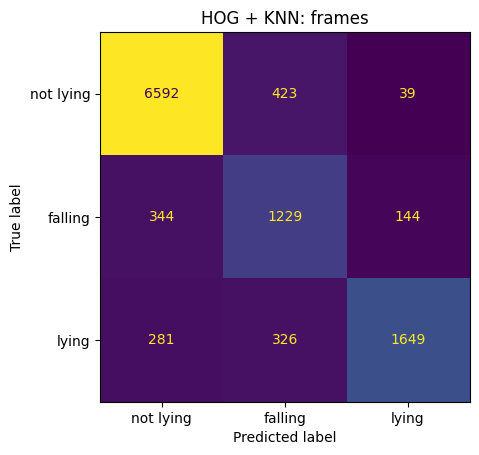

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = frame_scores.sort_values("macro F1").classifier.iloc[-1]
names = [PHASES[k] for k in (-1, 0, 1)]
print("best:", best)
print(classification_report(y, pred[best], target_names=names))
ConfusionMatrixDisplay.from_predictions(y, pred[best], display_labels=names, colorbar=False)
plt.title(f"HOG + {best}: frames"); plt.show()

💡 **Interpretation:** *not lying* is easy (F1 0.92), *lying* is good (0.81), *falling* is the hardest (0.67). Most errors are between **neighbouring** postures (not lying ↔ falling, lying → falling),
while *not lying* is almost never taken for *lying* (39 of 7,054): the confusions happen at the borders between phases, where postures really look alike.

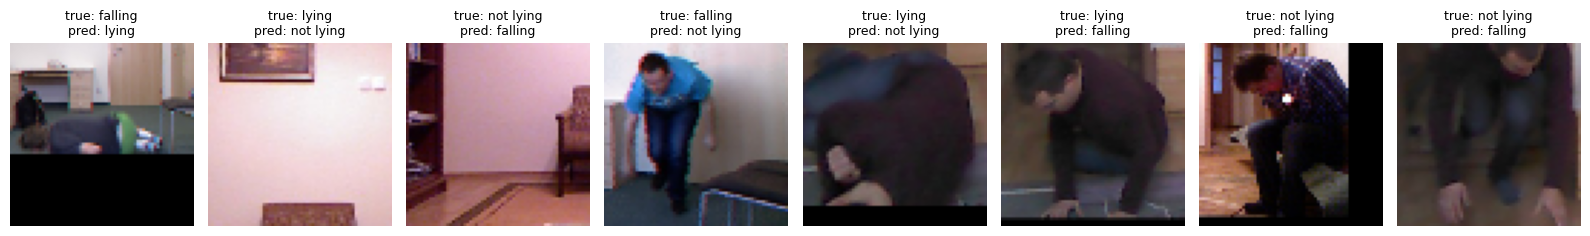

In [8]:
wrong = np.flatnonzero(pred[best] != y)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, rng.choice(wrong, 8, replace=False)):
    ax.imshow(crops[i]); ax.axis("off")
    ax.set_title(f"true: {PHASES[y[i]]}\npred: {PHASES[pred[best][i]]}", fontsize=9)
plt.tight_layout(); plt.show()

💡 **Interpretation:** two crops show **only the wall**: notebook 03 boxed something that is not the person, so no descriptor can be right there.
The others are **in-between postures** (bending, kneeling, getting up) where even the label is a matter of 1 or 2 frames.

## Step 7 — From frames to the whole video: fall or no fall?

For each video we count **which share of its frames** the classifier put in each posture (3 numbers that add up to 1). Then, exactly like the baseline (notebook 02), a **logistic regression** decides fall / no fall from these 3 numbers, tested with the **same 5 video groups**.

This step is the **same in notebooks 04 to 07**, so the descriptors are compared fairly.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score

def video_decision(frame_pred):
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    video_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return share, y_video, cross_val_predict(model, share, y_video, cv=video_cv)

rows, video_pred = [], {}
for name in classifiers:
    share, y_video, video_pred[name] = video_decision(pred[name])
    rows.append({"classifier": name, "video accuracy": accuracy_score(y_video, video_pred[name]),
                 "recall (falls)": recall_score(y_video, video_pred[name]),
                 "precision (falls)": precision_score(y_video, video_pred[name])})
video_scores = pd.DataFrame(rows).round(3)
print(share.groupby(y_video).mean().rename(index={0: "ADL videos", 1: "fall videos"}).round(2))
video_scores

             share not lying  share falling  share lying
ADL videos              0.83           0.05         0.12
fall videos             0.45           0.26         0.28


,classifier,video accuracy,recall (falls),precision (falls)
0,KNN,0.857,0.833,0.833
1,SVM,0.800,0.733,0.786
2,RF,0.829,0.767,0.821


💡 **Interpretation:** in fall videos the classifier puts about **26%** of frames in *falling* vs **5%** in ADLs: that is the main clue for the video decision.
Video accuracy: **0.857 with KNN** (25 of 30 falls caught), below the depth baseline (0.957) and the state machine (0.914).

## Step 8 — Which videos are wrong, and why?

In [10]:
share, y_video, _ = video_decision(pred[best])
length = labels.groupby("video").size()
wrong_videos = share.index[video_pred[best] != y_video]
print(f"HOG + {best}: {len(wrong_videos)} wrong videos")
print(pd.DataFrame({"frames in video": length[wrong_videos], "share lying": share.loc[wrong_videos, "share lying"].round(2),
                    "share falling": share.loc[wrong_videos, "share falling"].round(2)}))
print(f"\naverage length: fall videos {length[length.index.str.startswith('fall')].mean():.0f} frames, "
      f"ADL videos {length[length.index.str.startswith('adl')].mean():.0f} frames")

HOG + KNN: 10 wrong videos
         frames in video  share lying  share falling
video                                               
adl-31               250         0.33           0.34
adl-32               200         0.32           0.23
adl-33               200         0.28           0.24
adl-34               191         0.42           0.45
adl-35               280         0.42           0.45
fall-01              160         0.17           0.23
fall-03              215         0.15           0.16
fall-05              151         0.27           0.11
fall-07              156         0.22           0.21
fall-09              185         0.19           0.19

average length: fall videos 100 frames, ADL videos 214 frames


💡 **Interpretation:** the 5 missed falls are the **longest** fall videos (151-215 frames vs 100 on average): the fall is a smaller share of the video, so the shares look like an ADL.
The 5 false alarms (`adl-31`…`adl-35`) are people who **lie down on the floor on purpose**, with 28-42% of frames predicted *lying*: posture alone cannot see intention.

## Step 9 — Save the scores for the benchmark (notebook 08)

In [11]:
RESULTS = PROC / "results_traditional.csv"
scores = frame_scores.drop(columns="time (s)").merge(video_scores, on="classifier")
scores.insert(0, "descriptor", "HOG")
old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame()
if len(old):
    old = old[old.descriptor != "HOG"]
pd.concat([old, scores], ignore_index=True).to_csv(RESULTS, index=False)
scores

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,HOG,KNN,0.859,0.799,0.857,0.833,0.833
1,HOG,SVM,0.859,0.795,0.800,0.733,0.786
2,HOG,RF,0.855,0.770,0.829,0.767,0.821


💡 **Interpretation:** the 3 HOG rows are saved in `results_traditional.csv`; notebooks 05-07 add their own rows, and notebook 08 compares them all.

## What we learned

1. **HOG describes posture well:** 86% of frames get the right posture with any of the 3 classifiers; standing gives vertical edges, lying horizontal ones.
2. **The classifier matters less than the descriptor:** KNN, SVM and RF are within 0.004 in accuracy; KNN is the best (macro F1 0.799) and the fastest.
3. ***Falling* is the hard class** (F1 0.67): a fall lasts ~1 s and its frames look like the start (bending) or the end (on the floor).
4. **Video level: 0.857 accuracy** (HOG + KNN). Errors come from (a) long fall videos where the fall is a small share, (b) ADLs where people lie down on purpose: a **single frame** cannot tell a fall from lying down; we need **time / speed** (notebook 10 did that with skeletons).
5. **Limits:** some crops miss the person (notebook 03); the HOG grid also captures room edges.

**Next notebook (05):** the same pipeline with **LBP** (texture) instead of HOG (shape).